# 02 · Combine results

File: `combine_results.csv` (joined to `players.csv`).

**Questions:** Which measurables are missing and why? How do they differ by position? How do they relate to each other and to draft slot?

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from utils import *
set_style()
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 160)

In [2]:
comb = load_csv("combine_results")
players = load_csv("players")
print(comb.shape, "unique ids:", comb.nfl_id.nunique())
comb.head()

(510, 18) unique ids: 510


,draft_year,nfl_id,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
0,2023,56040,TE,77.875,245,10.000,32.250,79.750,1.60,4.84,38.5,125.0,NaN,NaN,NaN,60,NaN,NaN
1,2023,56010,DB,70.625,191,8.750,29.625,72.250,1.58,4.59,33.5,116.0,NaN,NaN,23.0,60,77.0,74.0
2,2023,56085,TE,79.375,255,10.250,34.000,83.125,1.57,4.55,40.0,128.0,6.87,4.12,23.0,97,65.0,79.0
3,2023,56056,WR,72.250,192,9.625,31.875,76.125,1.51,4.33,NaN,NaN,NaN,NaN,NaN,76,68.0,73.0
4,2023,56118,WR,71.625,191,9.500,31.000,75.000,1.52,4.54,38.5,120.0,6.98,4.15,14.0,65,65.0,64.0


In [3]:
missingness(comb)

,n_missing,pct_missing,dtype
three_cone,330,64.71,float64
bench_reps,318,62.35,float64
short_shuttle,309,60.59,float64
broad_jump,87,17.06,float64
forty,86,16.86,float64
ten_yd_split,85,16.67,float64
vertical,72,14.12,float64
ngs_college_production_score,1,0.20,float64
ngs_final_score,1,0.20,float64
nfl_id,0,0.00,int64


## Missingness by position group

,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,n
combine_position,,,,,,,,,,,
DB,0.0,0.0,0.0,0.15,0.15,0.14,0.20,0.80,0.73,0.63,122
DL,0.0,0.0,0.0,0.20,0.20,0.14,0.18,0.64,0.61,0.54,118
OL,0.0,0.0,0.0,0.21,0.21,0.17,0.19,0.50,0.47,0.56,121
TE,0.0,0.0,0.0,0.19,0.19,0.17,0.17,0.57,0.52,0.71,42
WR,0.0,0.0,0.0,0.09,0.09,0.10,0.11,0.69,0.64,0.74,107


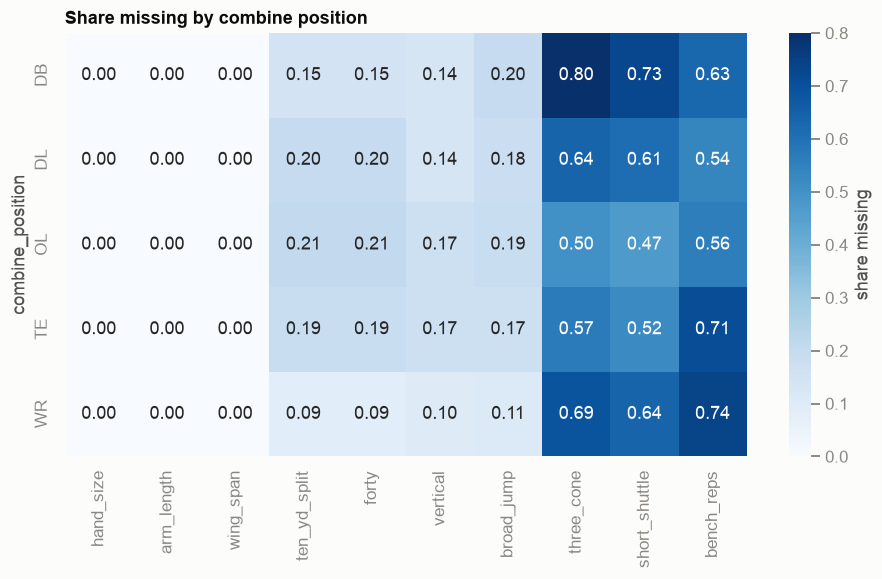

In [4]:
drills = ["hand_size","arm_length","wing_span","ten_yd_split","forty","vertical","broad_jump","three_cone","short_shuttle","bench_reps"]
miss = comb.groupby("combine_position")[drills].agg(lambda s: s.isna().mean()).round(2)
miss["n"] = comb.combine_position.value_counts()
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(miss[drills], annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "share missing"}, ax=ax); ax.set_title("Share missing by combine position")
savefig(fig, "02_missing")
miss

## Distributions by position

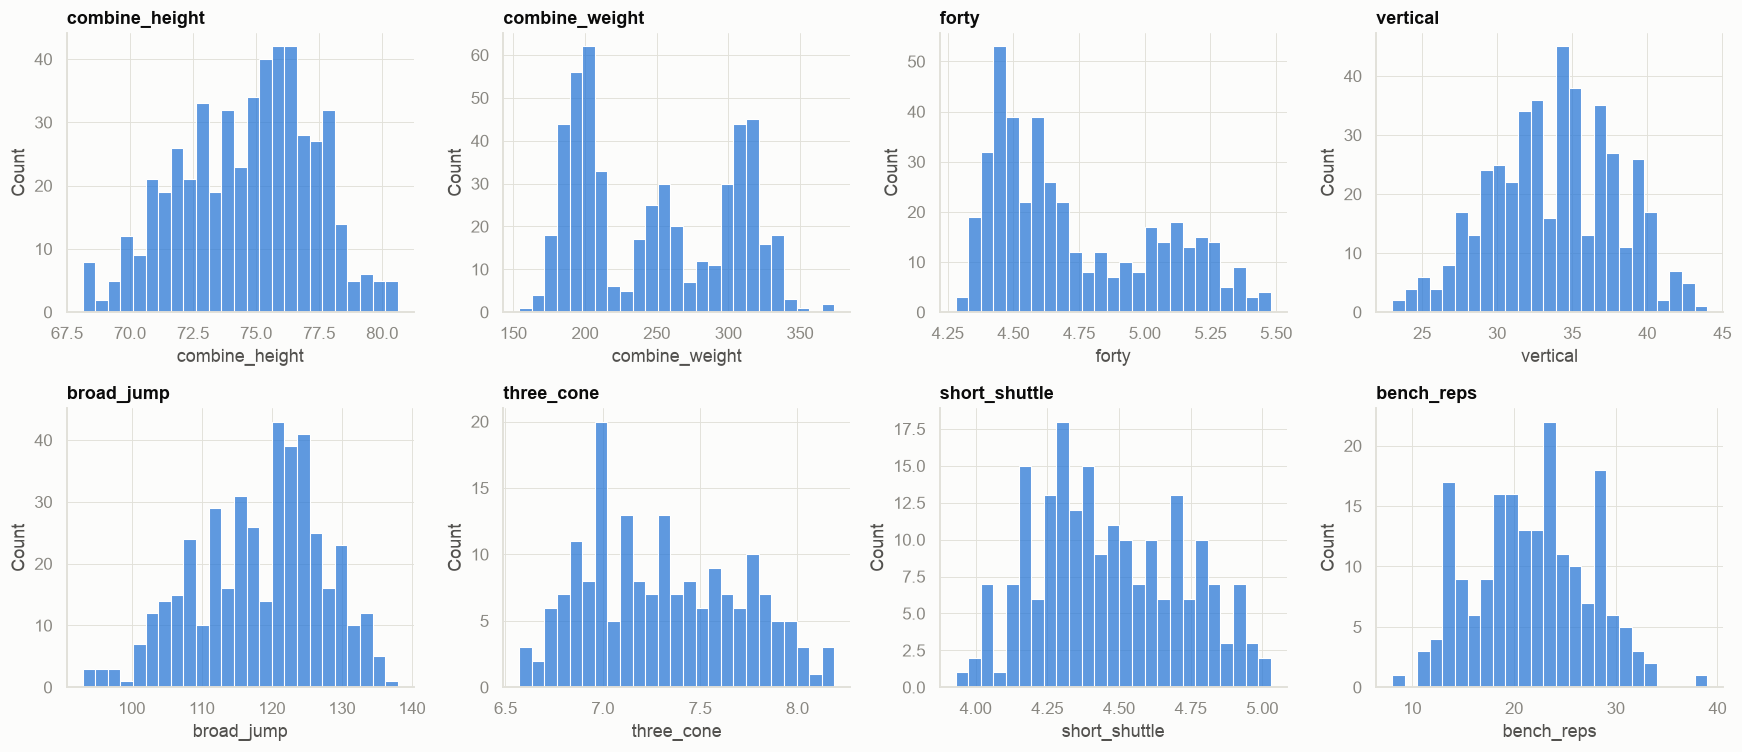

In [5]:
meas = ["combine_height","combine_weight","forty","vertical","broad_jump","three_cone","short_shuttle","bench_reps"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.flat, meas):
    sns.histplot(comb[c].dropna(), bins=25, color=PALETTE[0], ax=ax); ax.set_title(c)
plt.tight_layout(); savefig(fig, "02_dists")

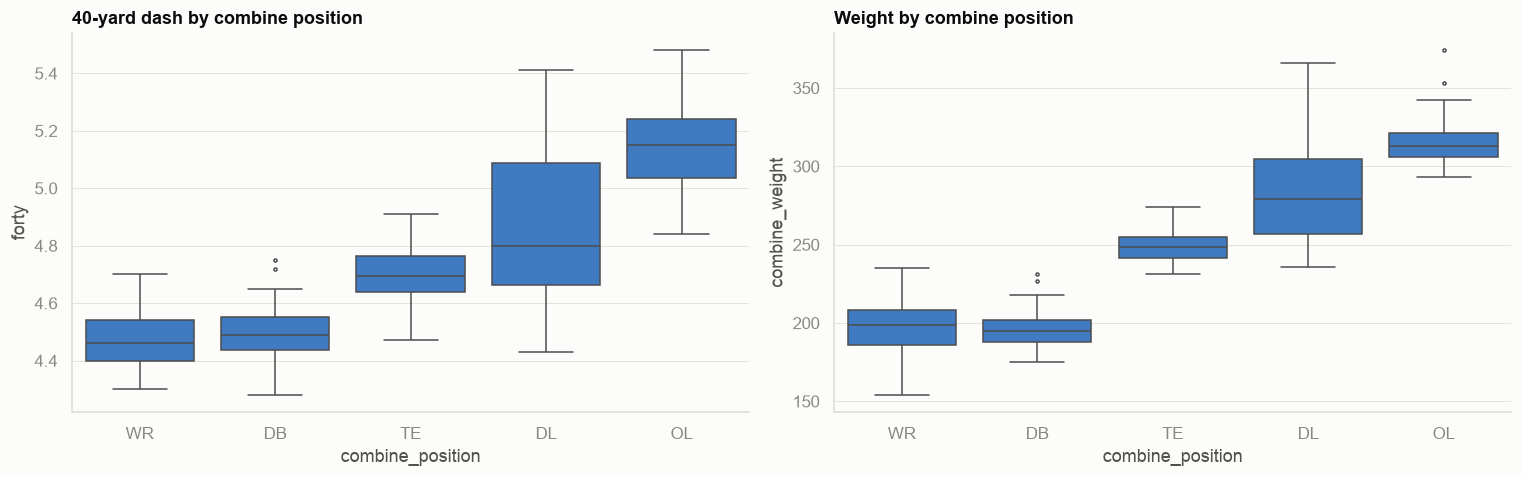

In [6]:
order = comb.groupby("combine_position").forty.median().sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=comb, x="combine_position", y="forty", order=order, color=PALETTE[0], fliersize=2, linewidth=1, ax=axes[0]); axes[0].set_title("40-yard dash by combine position")
sns.boxplot(data=comb, x="combine_position", y="combine_weight", order=order, color=PALETTE[0], fliersize=2, linewidth=1, ax=axes[1]); axes[1].set_title("Weight by combine position")
plt.tight_layout(); savefig(fig, "02_by_position")

## Relationships

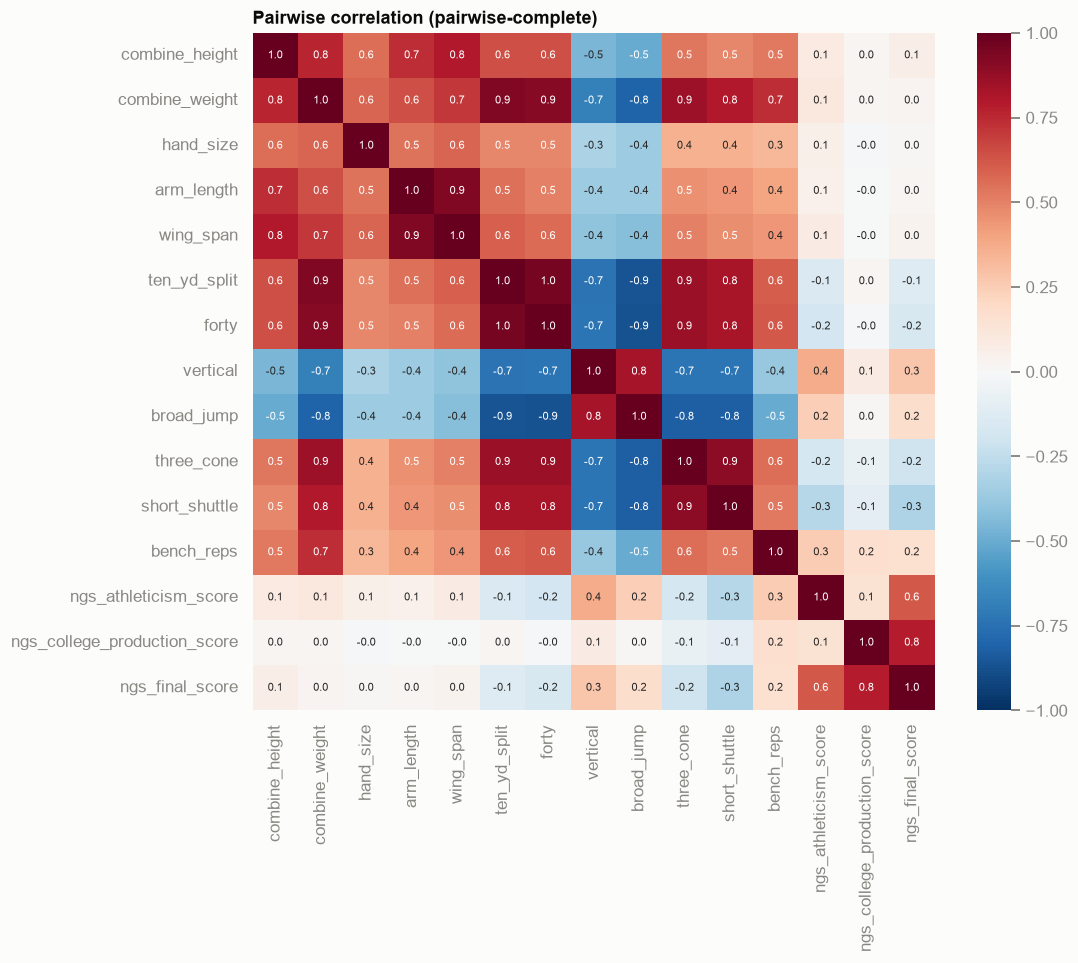

In [7]:
num = comb[["combine_height","combine_weight","hand_size","arm_length","wing_span","ten_yd_split","forty","vertical","broad_jump","three_cone","short_shuttle","bench_reps","ngs_athleticism_score","ngs_college_production_score","ngs_final_score"]]
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(num.corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f", annot_kws={"size": 7}, ax=ax); ax.set_title("Pairwise correlation (pairwise-complete)")
savefig(fig, "02_corr")

rows where 10yd split >= forty: 0


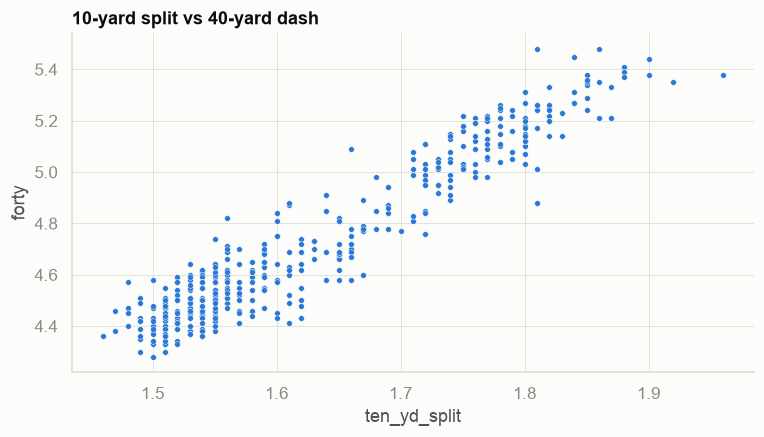

In [8]:
fig, ax = plt.subplots()
sns.scatterplot(data=comb, x="ten_yd_split", y="forty", s=14, color=PALETTE[0], ax=ax); ax.set_title("10-yard split vs 40-yard dash")
print("rows where 10yd split >= forty:", (comb.ten_yd_split >= comb.forty).sum())

## NGS scores vs draft capital

,draft_overall_pick,ngs_athleticism_score,ngs_college_production_score,ngs_final_score
draft_overall_pick,1.00,-0.30,-0.57,-0.68
ngs_athleticism_score,-0.30,1.00,0.15,0.61
ngs_college_production_score,-0.57,0.15,1.00,0.76
ngs_final_score,-0.68,0.61,0.76,1.00


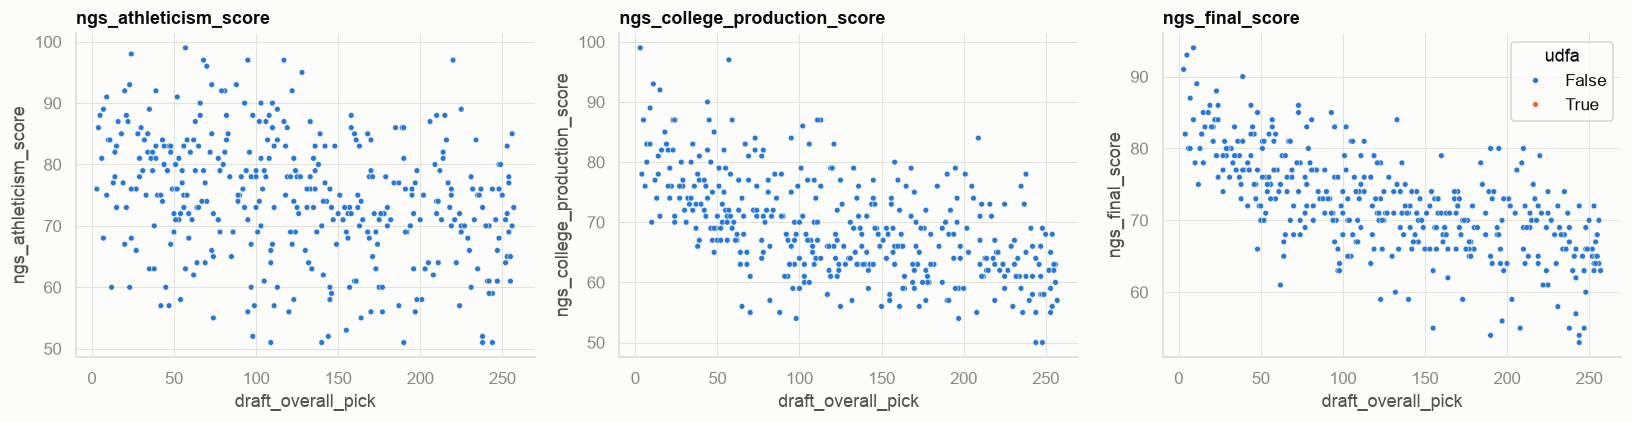

In [9]:
df = comb.merge(players[["nfl_id","draft_overall_pick","draft_round","nfl_position"]], on="nfl_id")
df["udfa"] = df.draft_overall_pick.isna()
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["ngs_athleticism_score","ngs_college_production_score","ngs_final_score"]):
    sns.scatterplot(data=df, x="draft_overall_pick", y=c, hue="udfa", palette=[PALETTE[0], PALETTE[1]], s=14, legend=(c == "ngs_final_score"), ax=ax); ax.set_title(c)
plt.tight_layout(); savefig(fig, "02_ngs_vs_pick")
df[["draft_overall_pick","ngs_athleticism_score","ngs_college_production_score","ngs_final_score"]].corr(method="spearman").round(2)

## Sanity checks

In [10]:
print("combine_position vs nfl_position mismatch (top):")
pd.crosstab(df.combine_position, df.nfl_position).stack().loc[lambda s: s > 0].sort_values(ascending=False).head(15)

combine_position vs nfl_position mismatch (top):


combine_position  nfl_position
WR                WR              106
DB                CB               60
OL                G                51
                  T                50
DL                DT               47
TE                TE               41
DL                DE               36
                  OLB              30
DB                SS               28
                  FS               25
OL                C                20
DB                DB                5
DL                NT                5
DB                ILB               2
                  MLB               1
dtype: int64

In [11]:
z = (num - num.mean()) / num.std()
out = z.abs().stack().loc[lambda s: s > 4]
print(len(out), "values with |z| > 4"); out.sort_values(ascending=False).head(15)

0 values with |z| > 4


Series([], dtype: float64)

## Findings / follow-ups
- Fill in after reviewing outputs.